# 10 — Todos los modelos: la línea de base

**Objetivo:** tener la foto completa de los 9 modelos de la tesis, evaluados
todos con **las mismas reglas**, antes de cambiar el preprocesamiento
(notebook 11). Al terminar deberías poder:
- decir en una o dos frases qué hace cada modelo;
- explicar la diferencia entre `class_weight` y SMOTE;
- contar tres problemas de configuración del código de la tesis y cómo se
  corrigen;
- leer una tabla con AUC, sensibilidad, especificidad y exactitud balanceada;
- decir qué tipos de patología distingue cada modelo;
- decir qué modelos se aprovechan de las grabaciones del mismo caso.

Las reglas son las de las notebooks 06 y 07: validación cruzada
estratificada de 5 particiones, repetida 3 veces, con las predicciones
out-of-fold; umbral 0,5; validación por grabación como principal y por caso
como comparación.

*(La notebook tarda unos 8 minutos en correr entera; las secciones 4 y 7 son
las más lentas.)*

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.evaluation import make_pipeline   # el mismo pipeline de la tesis: escalado -> (SMOTE) -> modelo
from src.paths import OUT_DIR

# Avisos de convergencia y de versiones de las librerías: no cambian los resultados
warnings.filterwarnings("ignore")

NO_FEATURES = ["file_id", "label", "label_binary"]
SEMILLA = 0
REPETICIONES = 3


def cargar(subset):
    df = pd.read_csv(OUT_DIR / f"{subset.lower()}_features.csv")
    X, y = df.drop(columns=NO_FEATURES), df["label_binary"].values
    caso = df["file_id"].str.split("_").str[:2].str.join("_").values   # género_tipo
    return X, y, caso, df["label"].values                               # label = tipo de sonido


datos = {s: cargar(s) for s in ["LS", "HS"]}
NOMBRE = {"LS": "Pulmonares", "HS": "Cardíacos"}


def puntajes(modelo, X, y, cv, grupos=None):
    """Probabilidad de 'patológico' out-of-fold. Los SVM no dan probabilidad: usamos su puntaje
    (la distancia a la frontera) pasado por una sigmoide fija, así 0,5 coincide con su frontera."""
    if hasattr(modelo, "predict_proba"):
        return cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="predict_proba")[:, 1]
    return 1 / (1 + np.exp(-cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="decision_function")))


def prob_validacion(modelo, X, y, repeticiones=REPETICIONES):
    """Predicciones out-of-fold (validación por grabación, 5 particiones), una lista por repetición."""
    return [puntajes(modelo, X, y, StratifiedKFold(5, shuffle=True, random_state=s)) for s in range(repeticiones)]


def metricas(y, probs, umbral=0.5):
    """AUC, sensibilidad, especificidad y exactitud balanceada, promediadas entre repeticiones."""
    filas = []
    for p in probs:
        tn, fp, fn, tp = confusion_matrix(y, p >= umbral, labels=[0, 1]).ravel()
        sens, esp = tp / (tp + fn), tn / (tn + fp)
        filas.append({"AUC": roc_auc_score(y, p), "sensibilidad": sens, "especificidad": esp,
                      "exactitud balanceada": (sens + esp) / 2})
    return pd.DataFrame(filas).mean()

## 1. Los 9 modelos, en pocas palabras

Dos ya los vimos a fondo: la **regresión logística** (notebook 08) y el
**random forest** (notebook 09, de consulta). Del resto alcanza con entender
la idea y qué controla cada parámetro.

**Regresión logística.** Suma las features multiplicadas por pesos y pasa el
resultado por la sigmoide. Separa con una frontera **recta**. Parámetro
principal: `C` (regularización).

**SVM lineal** (*support vector machine*, máquina de vectores de soporte).
También separa con una recta, pero la elige distinto: busca la recta que deja
el **mayor margen** posible entre las clases (la "calle" más ancha entre
normales y patológicos). Solo le importan las grabaciones que quedan cerca de
la frontera: los **vectores de soporte**. Parámetro: `C`, que regula cuánto
tolera grabaciones del lado equivocado (igual que en la regresión logística,
C grande = menos regularización).

**SVM-RBF.** El mismo SVM, pero con un *kernel* que le permite trazar
fronteras **curvas**: en vez de una recta, mide cuánto se parece cada
grabación a cada vector de soporte, como una "campana" alrededor de cada
uno. Parámetros: `C` y `gamma` (qué tan angosta es cada campana; la tesis usa
los valores por defecto).

*Un detalle de los SVM:* no dan una probabilidad, sino un **puntaje** (la
distancia a la frontera, con signo). scikit-learn puede convertirlo en
probabilidad con un ajuste aparte (*Platt*), pero con tan pocos datos ese
ajuste se distorsiona. La tesis calculaba el AUC del SVM con su puntaje, y
acá hacemos lo mismo: lo pasamos por una sigmoide fija, así el umbral 0,5
coincide con la frontera del SVM y el AUC no cambia.

**Árbol de decisión** (notebook 09). Preguntas de sí o no sobre las features.
La tesis lo limita a `max_depth=4` niveles.

**Random forest** (notebook 09). 300 árboles, cada uno con un remuestreo de
las grabaciones y sorteando features en cada pregunta, que votan.

**XGBoost y LightGBM (boosting).** También combinan muchos árboles, pero en
vez de entrenarlos por separado y promediarlos (como el bosque), los entrenan
**en secuencia**: cada árbol nuevo se concentra en corregir los errores que
dejaron los anteriores. Es como un equipo donde cada residente revisa justo
los casos en que el anterior se equivocó. Los árboles son chicos
(`max_depth=3`), cada uno aporta solo un poco (`learning_rate=0.1`, la "tasa
de aprendizaje") y se suman 200 (`n_estimators`). XGBoost y LightGBM son dos
implementaciones de la misma idea. Con pocos datos, el riesgo es terminar
corrigiendo ruido.

**Voting (votación).** Combina tres modelos distintos (regresión logística,
random forest y SVM-RBF) promediando sus probabilidades (votación *soft*). La
idea es la del bosque, pero con modelos diferentes: si se equivocan en
grabaciones distintas, el promedio compensa.

**MLP** (*multilayer perceptron*, perceptrón multicapa). Una red neuronal
chica: una capa de 16 "neuronas", cada una calcula un puntaje lineal (como
una regresión logística) y lo deja pasar solo si es positivo; la salida
combina esas 16. Parámetros: `hidden_layer_sizes=(16,)` (una capa de 16) y
`alpha` (regularización: al revés que C, alpha grande = más regularización).
Por la restricción p ≫ n, la tesis lo mantiene chiquito.

| Modelo | Frontera | ¿Estandarizar? | Parámetros de la tesis |
|---|---|---|---|
| Regresión logística | recta | sí | `C=1`, `max_iter=2000` |
| SVM lineal | recta (máximo margen) | sí | `C=1` |
| SVM-RBF | curva | sí | `C=1`, `gamma="scale"` |
| Árbol de decisión | escalones | no | `max_depth=4` |
| Random forest | escalones, promediados | no | `n_estimators=300` |
| XGBoost | escalones, sumados en secuencia | no | 200 árboles, `max_depth=3`, `learning_rate=0.1`, `subsample=0.9` |
| LightGBM | escalones, sumados en secuencia | no | 200 árboles, `max_depth=3`, `learning_rate=0.1` |
| Voting | mezcla de las tres | sí (por la RL y el SVM) | promedio de RL + RF + SVM-RBF |
| MLP | curva | sí | 16 neuronas, `alpha=0.01`, `early_stopping=True` |

El pipeline de la tesis estandariza siempre, aunque a los modelos de árboles
no les cambie nada (notebook 09).

## 2. El desbalance: `class_weight` o SMOTE

En pulmonares hay 12 normales y 38 patológicos; en cardíacos, 9 y 41. Si no
se hace nada, los modelos tienden a decir "patológico" a todo (notebook 06).
La tesis prueba dos estrategias:

**`class_weight="balanced"`**: no toca los datos; hace que equivocarse con un
normal **cueste más** que equivocarse con un patológico, para que las dos
clases pesen lo mismo en total (notebook 08).

**SMOTE**: **inventa normales sintéticos** hasta igualar la cantidad de
patológicos. Cada normal nuevo se ubica en algún punto de la línea entre un
normal real y uno de sus normales vecinos más parecidos (la tesis usa 3
vecinos). Se aplica **solo dentro de cada partición de entrenamiento** (por
eso va dentro del pipeline): si se aplicara antes de separar, habría
normales sintéticos de entrenamiento casi idénticos a normales de
validación. La tesis lo hace bien.

Así se ve SMOTE con dos features pulmonares (solo para ilustrar):

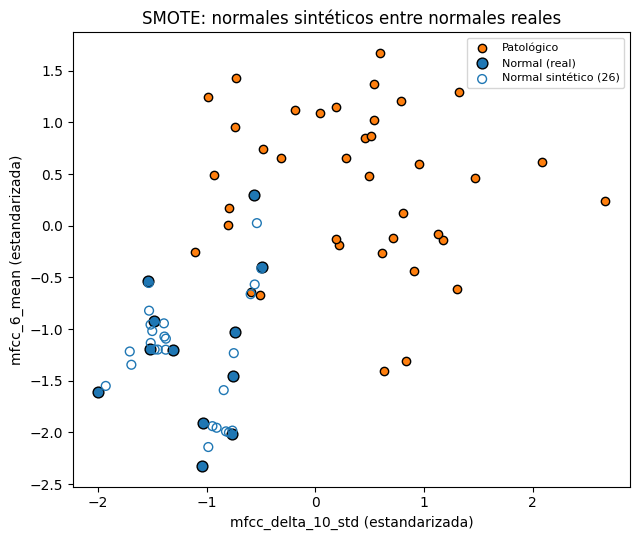

In [2]:
X_ls, y_ls, caso_ls, tipo_ls = datos["LS"]
DOS = ["mfcc_delta_10_std", "mfcc_6_mean"]   # las dos mejores features pulmonares solas (notebook 08)
x2 = StandardScaler().fit_transform(X_ls[DOS])
x_smote, y_smote = SMOTE(k_neighbors=3, random_state=SEMILLA).fit_resample(x2, y_ls)
sinteticos = x_smote[len(y_ls):]   # SMOTE agrega los sintéticos al final

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(x2[y_ls == 1, 0], x2[y_ls == 1, 1], c="tab:orange", edgecolor="k", label="Patológico")
ax.scatter(x2[y_ls == 0, 0], x2[y_ls == 0, 1], c="tab:blue", edgecolor="k", s=60, label="Normal (real)")
ax.scatter(sinteticos[:, 0], sinteticos[:, 1], facecolors="none", edgecolors="tab:blue", s=40,
           label=f"Normal sintético ({len(sinteticos)})")
ax.set(xlabel=f"{DOS[0]} (estandarizada)", ylabel=f"{DOS[1]} (estandarizada)",
       title="SMOTE: normales sintéticos entre normales reales")
ax.legend(fontsize=8)
fig.tight_layout()

Los círculos vacíos son los normales inventados: siempre caen **entre**
normales reales. SMOTE no agrega información nueva; rellena la zona donde ya
había normales.

## 3. Antes de comparar: tres configuraciones que no hacen lo que parecen

Revisando el código de la tesis aparecen tres problemas. No se ven en la
tabla de resultados: se ven mirando **cómo se entrena** cada modelo. Los
corregimos **antes** de comparar y con argumentos que no dependen de los
resultados (elegir correcciones mirando la tabla sería el mismo error que
elegir C mirando el AUC, notebook 08).

**1. XGBoost no estaba balanceado.** XGBoost no acepta `class_weight`; su
equivalente es `scale_pos_weight` (cuánto pesa la clase "patológico" respecto
de la "normal"). La tesis no lo usaba, así que en sus filas "class_weight",
XGBoost entrenó **sin ningún balanceo**. Corrección: `scale_pos_weight =
normales / patológicos` (calculado con todo el subconjunto; como las
particiones son estratificadas, la proporción es la misma en cada una). Con
SMOTE no cambia nada: SMOTE ya equilibra los datos.

**2. LightGBM arma árboles de una sola pregunta.** Por defecto, LightGBM exige
al menos 20 grabaciones en cada hoja (`min_child_samples=20`), un valor
pensado para miles de datos. Con unas 40 grabaciones de entrenamiento, la
única pregunta posible es la que las parte 20 y 20: cada árbol tiene 2 hojas,
y el `max_depth=3` de la tesis nunca llega a usarse. Corrección:
`min_child_samples=5`, para que un árbol de 3 niveles (hasta 8 hojas) sea
posible con 40 grabaciones (40 / 8 = 5).

**3. El MLP casi no entrena.** Con `early_stopping=True`, el MLP aparta el
10 % de sus datos de entrenamiento (unas 6 grabaciones, contando los normales
sintéticos de SMOTE) y deja de entrenar cuando el acierto en esas pocas no
mejora durante 10 vueltas seguidas. Con tan pocas, eso pasa enseguida.
Corrección: sin `early_stopping`; la regularización ya la da `alpha`.

(El MLP tampoco acepta `class_weight`, así que se balancea con SMOTE en los
dos casos: por eso sus dos filas en la tabla de la tesis son idénticas.)

In [3]:
CORREGIDOS = ["XGBoost", "LightGBM", "MLP"]


def modelos(balanceo, y, corregido=False):
    """Los 9 modelos de la tesis (Tabla 7.1). Con corregido=True, XGBoost, LightGBM y el MLP
    llevan las correcciones de esta sección."""
    cw = "balanced" if balanceo == "class_weight" else None
    peso_xgb = (y == 0).sum() / (y == 1).sum() if (cw and corregido) else 1   # el "class_weight" de XGBoost
    return {
        "Regresión logística": make_pipeline(LogisticRegression(max_iter=2000, class_weight=cw), balanceo),
        "SVM lineal": make_pipeline(SVC(kernel="linear", class_weight=cw), balanceo),
        "SVM-RBF": make_pipeline(SVC(kernel="rbf", class_weight=cw), balanceo),
        "Árbol de decisión": make_pipeline(DecisionTreeClassifier(max_depth=4, class_weight=cw,
                                                                  random_state=SEMILLA), balanceo),
        "Random forest": make_pipeline(RandomForestClassifier(n_estimators=300, class_weight=cw,
                                                              random_state=SEMILLA), balanceo),
        "XGBoost": make_pipeline(XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9,
                                               scale_pos_weight=peso_xgb, eval_metric="logloss",
                                               random_state=SEMILLA, n_jobs=1), balanceo),
        "LightGBM": make_pipeline(LGBMClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                                                 class_weight=cw, min_child_samples=5 if corregido else 20,
                                                 random_state=SEMILLA, verbose=-1, n_jobs=1), balanceo),
        "Voting": make_pipeline(VotingClassifier([
            ("rl", LogisticRegression(max_iter=2000, class_weight=cw)),
            ("rf", RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=SEMILLA)),
            ("svm", SVC(probability=True, class_weight=cw, random_state=SEMILLA))], voting="soft"), balanceo),
        # El MLP no acepta class_weight: se balancea siempre con SMOTE (como en la tesis)
        "MLP": make_pipeline(MLPClassifier(hidden_layer_sizes=(16,), alpha=1e-2, early_stopping=not corregido,
                                           max_iter=1000, random_state=SEMILLA), balanceo, force_smote=True),
    }

Lo verificamos mirando solo el **entrenamiento** (en las 5 particiones de
entrenamiento de pulmonares): cuántas vueltas entrena el MLP y cuántas hojas
tienen los árboles de LightGBM.

In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
for corregido, etiqueta in [(False, "tesis"), (True, "corregido")]:
    vueltas, hojas = [], []
    for entrenamiento, _ in cv.split(X_ls, y_ls):
        X_tr, y_tr = X_ls.iloc[entrenamiento], y_ls[entrenamiento]
        m = modelos("class_weight", y_ls, corregido)
        vueltas.append(m["MLP"].fit(X_tr, y_tr)[-1].n_iter_)
        lgbm = m["LightGBM"].fit(X_tr, y_tr)[-1]
        hojas += [arbol["num_leaves"] for arbol in lgbm.booster_.dump_model()["tree_info"]]
    print(f"{etiqueta:>9}: el MLP entrena {vueltas} vueltas; los árboles de LightGBM tienen "
          f"entre {min(hojas)} y {max(hojas)} hojas")

    tesis: el MLP entrena [12, 12, 13, 12, 14] vueltas; los árboles de LightGBM tienen entre 2 y 2 hojas


corregido: el MLP entrena [255, 266, 272, 260, 247] vueltas; los árboles de LightGBM tienen entre 2 y 7 hojas


Con la configuración de la tesis, el MLP para a las 12–14 vueltas y todos
los árboles de LightGBM tienen 2 hojas (una sola pregunta). Con las
correcciones, el MLP entrena unas 250 vueltas y LightGBM arma árboles de
varias hojas.

## 4. La comparación por grabación (la principal)

Entrenamos y validamos los 9 modelos con las dos estrategias de balanceo, en
los dos subconjuntos, y para XGBoost, LightGBM y el MLP también la versión
corregida: (9 + 3) × 2 × 2 = 48 combinaciones, cada una con 3 repeticiones
de la validación cruzada de 5 particiones. *(Esta celda tarda un par de
minutos.)*

In [5]:
BALANCEOS = ["class_weight", "smote"]
probs = {}   # (subconjunto, balanceo, modelo, versión) -> predicciones out-of-fold de cada repetición
for subset, (X, y, caso, tipo) in datos.items():
    for balanceo in BALANCEOS:
        for nombre, modelo in modelos(balanceo, y).items():
            probs[(subset, balanceo, nombre, "tesis")] = prob_validacion(modelo, X, y)
        for nombre in CORREGIDOS:
            probs[(subset, balanceo, nombre, "corregido")] = prob_validacion(modelos(balanceo, y, True)[nombre], X, y)
    print(f"{NOMBRE[subset]}: listo")


def finales(subset, balanceo, nombre):
    """Las predicciones del modelo en su versión final (corregida, si la tiene)."""
    return probs.get((subset, balanceo, nombre, "corregido"), probs[(subset, balanceo, nombre, "tesis")])

Pulmonares: listo


Cardíacos: listo


Para cada subconjunto, una tabla con las cuatro métricas para cada
estrategia de balanceo, ordenada por AUC (con `class_weight`). Como
referencia, agregamos el "modelo" inventado de la notebook 06, que dice
siempre "patológico". Para el AUC agregamos su **intervalo de confianza del
95 %** por bootstrap (notebook 07): cuánto podría cambiar con otra muestra
parecida de grabaciones.

Abreviaturas: *sens.* = sensibilidad, *esp.* = especificidad, *exact. bal.* =
exactitud balanceada (el promedio de las dos).

In [6]:
def ic_auc(y, probs_modelo, n=500):
    """IC 95 % bootstrap del AUC promedio entre repeticiones (remuestreando grabaciones)."""
    rng = np.random.default_rng(SEMILLA)
    valores = []
    while len(valores) < n:
        m = rng.integers(0, len(y), len(y))
        if len(np.unique(y[m])) == 2:
            valores.append(np.mean([roc_auc_score(y[m], p[m]) for p in probs_modelo]))
    return np.percentile(valores, [2.5, 97.5])


CORTO = {"sensibilidad": "sens.", "especificidad": "esp.", "exactitud balanceada": "exact. bal."}


def filas_modelos(subset, balanceo):
    """{nombre que se muestra: predicciones}, con las dos versiones de los modelos corregidos."""
    X, y, caso, tipo = datos[subset]
    filas = {}
    for nombre in modelos(balanceo, y):
        if nombre in CORREGIDOS:
            filas[f"{nombre} (tesis)"] = probs[(subset, balanceo, nombre, "tesis")]
            filas[f"{nombre} (corregido)"] = probs[(subset, balanceo, nombre, "corregido")]
        else:
            filas[nombre] = probs[(subset, balanceo, nombre, "tesis")]
    return filas


def tabla(subset):
    X, y, caso, tipo = datos[subset]
    bloques = {}
    for balanceo in BALANCEOS:
        filas = filas_modelos(subset, balanceo)
        bloque = pd.DataFrame({n: metricas(y, p) for n, p in filas.items()}).T
        bloque.loc["referencia: siempre 'patológico'"] = metricas(y, [np.ones(len(y))])
        bloque = bloque.round(2).rename(columns=CORTO)
        if balanceo == "class_weight":
            ic = {n: ic_auc(y, p) for n, p in filas.items()}
            bloque.insert(1, "IC 95 %", pd.Series({n: f"{a:.2f}–{b:.2f}" for n, (a, b) in ic.items()}))
        bloques[balanceo] = bloque
    return pd.concat(bloques, axis=1).sort_values(("class_weight", "AUC"), ascending=False)


for subset in datos:
    print(f"\n===== {NOMBRE[subset]} =====")
    print(tabla(subset).to_string(na_rep="—"))


===== Pulmonares =====


                                 class_weight                                    smote                        
                                          AUC    IC 95 % sens.  esp. exact. bal.   AUC sens.  esp. exact. bal.
Regresión logística                      1.00  1.00–1.00  0.98  0.94        0.96  1.00  0.98  0.92        0.95
SVM lineal                               1.00  0.99–1.00  0.99  0.89        0.94  1.00  0.99  0.89        0.94
Voting                                   0.99  0.97–1.00  0.99  0.78        0.88  0.99  0.99  0.78        0.88
SVM-RBF                                  0.98  0.94–1.00  0.98  0.72        0.85  0.97  0.98  0.67        0.82
Random forest                            0.95  0.88–0.99  0.99  0.64        0.82  0.94  0.97  0.69        0.83
MLP (corregido)                          0.94  0.83–1.00  0.91  0.86        0.89  0.94  0.91  0.86        0.89
XGBoost (corregido)                      0.93  0.85–0.98  0.91  0.75        0.83  0.91  0.93  0.67        0.80
X

                                 class_weight                                    smote                        
                                          AUC    IC 95 % sens.  esp. exact. bal.   AUC sens.  esp. exact. bal.
XGBoost (corregido)                      0.82  0.68–0.94  0.89  0.59        0.74  0.78  0.87  0.44        0.66
XGBoost (tesis)                          0.80  0.65–0.93  0.94  0.33        0.64  0.78  0.87  0.44        0.66
Random forest                            0.79  0.65–0.91  0.98  0.07        0.53  0.80  0.92  0.41        0.66
MLP (corregido)                          0.77  0.60–0.91  0.85  0.52        0.69  0.77  0.85  0.52        0.69
LightGBM (corregido)                     0.77  0.62–0.89  0.92  0.41        0.66  0.75  0.86  0.30        0.58
SVM-RBF                                  0.73  0.54–0.91  0.88  0.37        0.62  0.72  0.94  0.30        0.62
Voting                                   0.72  0.53–0.89  0.93  0.26        0.60  0.75  0.93  0.30        0.61
L

**Cómo leerla:**

**Pulmonares.** Arriba quedan los modelos **lineales**: la regresión
logística y el SVM lineal, con AUC ~1,00 y la mejor especificidad (0,94 y
0,89). Con una señal tan clara, una frontera recta alcanza, y los modelos
más flexibles no suman: el random forest y el boosting ordenan un poco peor y
reconocen menos normales.

**Cardíacos.** Todo es más bajo y más incierto. Arriba quedan los que
combinan árboles (XGBoost corregido 0,82, random forest 0,79) y el MLP
corregido (0,77); los lineales quedan abajo (regresión logística 0,68, SVM
lineal 0,62). Pero mirá los **intervalos de confianza**: el de XGBoost va de
0,68 a 0,94 y el de la regresión logística, de 0,48 a 0,87. Se superponen
muchísimo. Con 50 grabaciones **no se puede afirmar que un modelo sea mejor
que otro** en cardíacos. Lo que sí se puede decir es qué modelos son mejores
que el azar: en su versión final, los intervalos de seis modelos quedan por
encima de 0,5, pero los de la regresión logística, el SVM lineal y el árbol
solo incluyen el 0,5.

**Las correcciones importan:**
- El **MLP** de la tesis no aprendía: en pulmonares daba un AUC de 0,44 (peor
  que el azar) y en cardíacos decía "normal" a casi todo (sensibilidad 0,21).
  Corregido, queda entre los buenos (0,94 y 0,77).
- **XGBoost** balanceado reconoce muchos más normales con un AUC parecido: la
  especificidad pasa de 0,58 a 0,75 en pulmonares y de 0,33 a 0,59 en
  cardíacos.
- **LightGBM** con árboles de verdad mejora en los dos subconjuntos (de 0,87
  a 0,90 y de 0,69 a 0,77).

**`class_weight` contra SMOTE:** no hay un ganador general; en la mayoría de
los modelos dan resultados parecidos. Las diferencias más grandes: en
cardíacos, con SMOTE el random forest reconoce muchos más normales
(especificidad de 0,07 a 0,41, por lo que vimos en la notebook 09), y XGBoost
corregido, al revés, funciona mejor con su peso de clases (0,59 contra 0,44);
en pulmonares, LightGBM corregido también funciona mejor con su peso de
clases (0,67 contra 0,47).

*(Los AUC no coinciden exactamente con la tabla de la tesis porque acá se
calculan con todas las predicciones out-of-fold juntas, como en la notebook
07, y la tesis promediaba el AUC de cada partición. Además, el MLP, XGBoost y
LightGBM ahora llevan las correcciones.)*

## 5. ¿Cuál es el mejor?

El mismo resultado en un gráfico, con cada modelo en su versión final y con
`class_weight`: cada punto es un modelo, ubicado según su especificidad y su
sensibilidad con el umbral 0,5. El rincón ideal es arriba a la derecha.

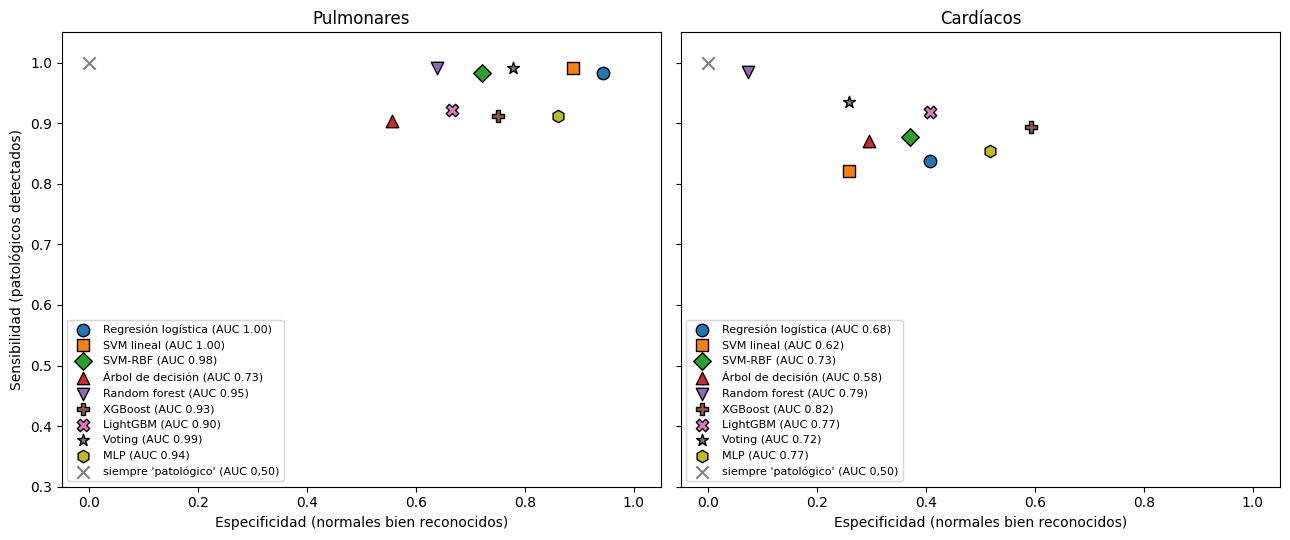

In [7]:
MARCAS = ["o", "s", "D", "^", "v", "P", "X", "*", "h"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, subset in zip(axes, datos):
    X, y, caso, tipo = datos[subset]
    for marca, nombre in zip(MARCAS, modelos("class_weight", y)):
        m = metricas(y, finales(subset, "class_weight", nombre))
        ax.scatter(m["especificidad"], m["sensibilidad"], s=80, marker=marca, edgecolor="k",
                   label=f"{nombre} (AUC {m['AUC']:.2f})")
    ax.scatter(0, 1, marker="x", s=80, c="gray", label="siempre 'patológico' (AUC 0,50)")
    ax.set(xlim=(-0.05, 1.05), ylim=(0.3, 1.05), xlabel="Especificidad (normales bien reconocidos)",
           title=NOMBRE[subset])
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_ylabel("Sensibilidad (patológicos detectados)")
fig.tight_layout()

**Cómo leerlo:**
- En **pulmonares** casi todos están arriba (sensibilidad de 0,9 o más), y lo
  que los distingue es la **especificidad**: la regresión logística (0,94) y
  el SVM lineal (0,89) reconocen casi todos los normales; el árbol solo
  (0,56) y el random forest (0,64), bastante menos.
- En **cardíacos** todos quedan en la mitad izquierda: con el umbral 0,5,
  **ningún modelo reconoce bien a los normales** (la mejor especificidad es
  0,59, la de XGBoost). El random forest queda casi pegado a la referencia
  "siempre patológico".

**Entonces, ¿cuál es el mejor?**
- **Pulmonares: la regresión logística.** Tiene el mejor AUC y la mejor
  especificidad, y además es la más simple y la más fácil de explicar
  (notebook 08). Cuando un modelo simple empata o gana, se elige el simple.
- **Cardíacos: no hay un ganador claro.** XGBoost corregido tiene el mejor AUC
  y la mejor exactitud balanceada (0,74), pero su intervalo se superpone con
  los de casi todos. Lo honesto para la tesis es decir eso: con estos datos y
  estas features, ningún modelo se separa de los demás. El problema cardíaco
  no se resuelve cambiando de modelo, y la pregunta pasa al preprocesamiento
  y a las features (notebook 11).

## 6. ¿Qué tipos de patología distingue cada modelo?

"Patológico" mezcla cosas muy distintas. Para cada tipo de patología
calculamos un AUC **usando solo los normales y las grabaciones de ese tipo**:
si tomamos un normal y una grabación de ese tipo al azar, ¿con qué
probabilidad el modelo le da más puntaje a la patológica? (Versión final de
cada modelo, con `class_weight`.)

**Cuidado:** hay entre 2 y 9 grabaciones por tipo, así que cada número es muy
ruidoso. Sirve para ver **patrones** (qué filas o columnas son
sistemáticamente altas o bajas), no para comparar decimales.

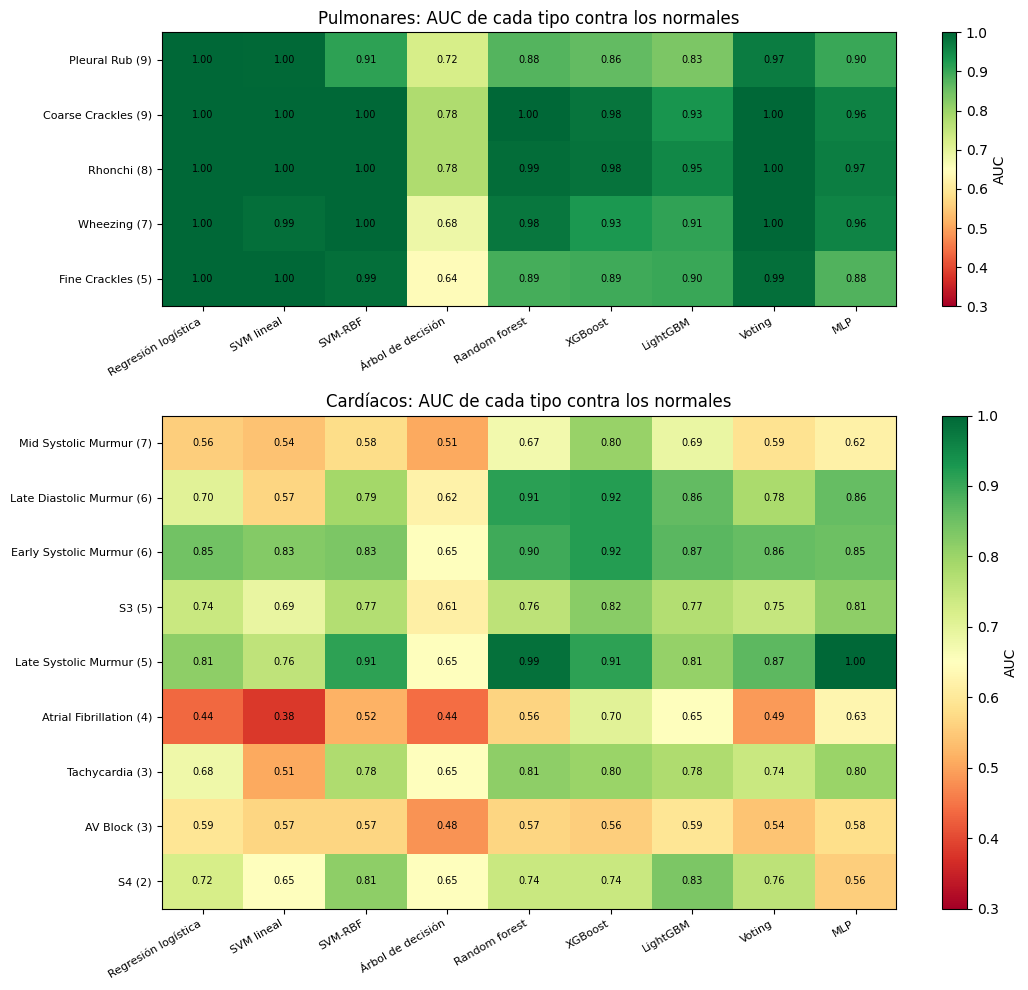

In [8]:
def auc_por_tipo(subset, balanceo="class_weight"):
    X, y, caso, tipo = datos[subset]
    normales = tipo == "Normal"
    tipos = pd.Series(tipo[~normales]).value_counts().index
    resultado = {}
    for nombre in modelos(balanceo, y):
        resultado[nombre] = {}
        for t in tipos:
            etiquetas = np.r_[np.zeros(normales.sum()), np.ones((tipo == t).sum())]
            resultado[nombre][f"{t} ({(tipo == t).sum()})"] = np.mean(
                [roc_auc_score(etiquetas, np.r_[p[normales], p[tipo == t]]) for p in finales(subset, balanceo, nombre)])
    return pd.DataFrame(resultado)


fig, axes = plt.subplots(2, 1, figsize=(11, 10), gridspec_kw={"height_ratios": [5, 9]})
for ax, subset in zip(axes, datos):
    t = auc_por_tipo(subset)
    imagen = ax.imshow(t.values, cmap="RdYlGn", vmin=0.3, vmax=1, aspect="auto")
    ax.set(xticks=range(t.shape[1]), yticks=range(t.shape[0]),
           title=f"{NOMBRE[subset]}: AUC de cada tipo contra los normales")
    ax.set_xticklabels(t.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticklabels(t.index, fontsize=8)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(imagen, ax=ax, label="AUC")
fig.tight_layout()

**Cómo leerlo:**
- **Pulmonares:** casi todo verde. Todos los tipos se distinguen bien de los
  normales con casi todos los modelos; solo el árbol solo queda atrás. Los
  modelos de árboles (y el MLP) tienen algo más de dificultad con el **roce
  pleural** y los **crepitantes finos**.
- **Cardíacos:** el patrón es por **fila** (por tipo de patología), no por
  columna (por modelo):
  - Los soplos **sistólicos precoces y tardíos** y el **diastólico tardío** se
    distinguen bastante bien con la mayoría de los modelos (0,7 a 1,0).
  - La **fibrilación auricular** (de 0,38 a 0,70) y el **bloqueo AV** (de
    0,48 a 0,59) quedan cerca del azar con casi todos los modelos: casi
    ninguno los distingue de un normal. Son trastornos del **ritmo**, y las
    features actuales (promedios y desvíos de cada trama) pierden el orden
    temporal, como vimos en las notebooks 03 y 04.
  - El **soplo mesosistólico** también cuesta (de 0,51 a 0,80).
  - La **taquicardia**, aunque también es de ritmo, se distingue algo mejor:
    cambia la cantidad de latidos por segundo, y eso sí altera las
    estadísticas de las tramas.

Esto confirma lo que sospechabas: **lo que usamos no sirve para las
arritmias**, y ningún modelo lo compensa. Es un argumento fuerte para sumar
las features de ritmo (notebook 04) en la notebook 11, y para reportar los
resultados por tipo de patología en la tesis.

## 7. La validación por caso, con el control de pseudo-casos (comparación)

Repetimos para todos los modelos (versión final, `class_weight`) el control
de las notebooks 07 y 09: validación por caso real (dejar un caso afuera por
vez) y por **pseudo-casos** (grupos al azar del mismo tamaño y clase, 5
sorteos, los mismos para todos los modelos).
- Si el caso real da **por debajo de todos** los pseudo-casos, hay una
  **fuga** real: el modelo se aprovecha de la grabación "hermana".
- Si cae **dentro** del rango, la caída respecto de la validación por
  grabación viene del **esquema** (dejar afuera grupos enteros de una clase),
  no de la fuga.

*(Esta es la celda más lenta: entrena cada modelo unas 190 veces. Tarda
unos 4 minutos.)*

In [9]:
def pseudo_casos(caso, y, rng):
    """Grupos al azar con los mismos tamaños y la misma clase que los casos reales (notebook 07)."""
    nuevo = np.empty(len(caso), dtype=object)
    for clase in [0, 1]:
        indices = rng.permutation(np.where(y == clase)[0])
        tamanios = pd.Series(caso[y == clase]).value_counts().values
        inicio = 0
        for j, t in enumerate(tamanios):
            nuevo[indices[inicio:inicio + t]] = f"pseudo_{clase}_{j}"
            inicio += t
    return nuevo


def auc_por_grupos(modelo, X, y, grupos):
    return roc_auc_score(y, puntajes(modelo, X, y, LeaveOneGroupOut(), grupos))


SORTEOS = 5
filas = []
for subset, (X, y, caso, tipo) in datos.items():
    rng = np.random.default_rng(SEMILLA)
    sorteos = [pseudo_casos(caso, y, rng) for _ in range(SORTEOS)]
    for nombre, modelo in modelos("class_weight", y, corregido=True).items():
        pseudo = [auc_por_grupos(modelo, X, y, g) for g in sorteos]
        real = auc_por_grupos(modelo, X, y, caso)
        filas.append({"subconjunto": NOMBRE[subset], "modelo": nombre,
                      "por grabación": metricas(y, finales(subset, "class_weight", nombre))["AUC"],
                      "pseudo-caso (media)": np.mean(pseudo),
                      "pseudo-caso (mín–máx)": f"{np.min(pseudo):.2f}–{np.max(pseudo):.2f}",
                      "caso real": real,
                      "¿fuga?": "sí" if real < np.min(pseudo) else "no medible"})
    print(f"{NOMBRE[subset]}: listo")
control = pd.DataFrame(filas)
print(control.round(3).to_string(index=False))

Pulmonares: listo


Cardíacos: listo
subconjunto              modelo  por grabación  pseudo-caso (media) pseudo-caso (mín–máx)  caso real     ¿fuga?
 Pulmonares Regresión logística          1.000                0.988             0.98–1.00      0.967         sí
 Pulmonares          SVM lineal          0.997                0.983             0.98–1.00      0.914         sí
 Pulmonares             SVM-RBF          0.977                0.924             0.90–0.96      0.882         sí
 Pulmonares   Árbol de decisión          0.730                0.626             0.53–0.75      0.533 no medible
 Pulmonares       Random forest          0.949                0.857             0.77–0.89      0.755         sí
 Pulmonares             XGBoost          0.931                0.796             0.77–0.83      0.684         sí
 Pulmonares            LightGBM          0.904                0.817             0.73–0.91      0.741 no medible
 Pulmonares              Voting          0.991                0.968             0.95–0.

**Cómo leerlo:**

**Pulmonares:** en casi todos los modelos, el caso real da **por debajo de
todos** los pseudo-casos: se aprovechan, en alguna medida, de la grabación
hermana. El tamaño de la fuga (pseudo-caso medio menos caso real) cambia
mucho según el modelo:
- **chica** en la regresión logística (~0,02);
- **intermedia** en el SVM-RBF, el Voting y el MLP (~0,04) y en el SVM lineal
  (~0,07);
- **grande** en el random forest (~0,10) y XGBoost (~0,11), los que combinan
  muchos árboles.

En el árbol solo y en LightGBM el caso real queda dentro del rango, aunque
cerca del borde de abajo: con 5 sorteos no alcanza para afirmar que haya fuga.

**Cardíacos:** en **ningún** modelo el caso real cae por debajo de los
pseudo-casos: **no hay fuga medible**. Pero varios modelos caen mucho con los
pseudo-casos (el SVM-RBF de 0,73 a 0,47, el Voting de 0,72 a 0,49, el random
forest de 0,79 a 0,53). Es el efecto del **esquema** que vimos en la notebook
09: con solo dos casos normales, dejar uno afuera deja muy pocos normales para
entrenar, y la escala de los puntajes se corre.

**Para la tesis (secciones 8.1.1 y 8.5.2):** el "optimismo" de la validación
por grabación tiene dos componentes que conviene separar:
1. la **fuga por caso**, real en pulmonares, mayor en los modelos que combinan
   muchos árboles y casi nula en la regresión logística;
2. el **efecto del esquema**, que domina en cardíacos y no es memorización.

Por eso la validación por grabación sigue siendo la principal, y la
validación por caso, con este control, queda como el análisis complementario.

## 8. Qué nos llevamos a la notebook 11

1. **Las tres correcciones** (XGBoost balanceado, LightGBM con
   `min_child_samples=5` y el MLP sin `early_stopping`) quedan como la versión
   de los modelos de acá en adelante. Hay que pasarlas también a los `.py`
   finales.
2. **Pulmonares está prácticamente resuelto** con la regresión logística. Ahí
   la pregunta de la notebook 11 no es cómo mejorar, sino si el resultado
   **depende de cosas no fisiológicas** (el volumen y el tono de 146 Hz,
   notebook 02): si se mantiene al filtrar y normalizar, es más creíble.
3. **Cardíacos es donde hay margen, y el modelo no es el cuello de botella:**
   ningún modelo se separa de los demás, y las arritmias quedan cerca del
   azar con casi todos. La notebook 11 prueba los preprocesamientos
   candidatos y las **features de ritmo**.
4. **Qué modelos llevar.** Para que la notebook 11 no tarde horas, te propongo
   llevar cuatro modelos representativos, elegidos por el **tipo** de modelo y
   no por su resultado: la **regresión logística** (lineal, la que explicamos
   a fondo), el **SVM-RBF** (frontera curva), el **random forest** (árboles
   promediados) y **XGBoost** (árboles en secuencia). Con `class_weight`, que
   es más simple y no inventa datos.
5. **Reportar siempre** el AUC con su intervalo, la sensibilidad, la
   especificidad, la exactitud balanceada y el AUC por tipo de patología.

## 9. Cómo explicárselo a tu directora (en 5 frases)

1. *"Comparé los 9 modelos de la tesis con las mismas reglas: validación
   cruzada estratificada repetida, por grabación; AUC con intervalo de
   confianza, sensibilidad, especificidad y exactitud balanceada, y además el
   AUC de cada tipo de patología contra los normales."*
2. *"Antes de comparar corregí tres configuraciones que no hacían lo que
   parecían: XGBoost no estaba balanceado, LightGBM armaba árboles de una sola
   pregunta y el MLP dejaba de entrenar a las 12 vueltas; corregido, el MLP
   pasa de no aprender a estar entre los buenos."*
3. *"En pulmonares, la regresión logística es la mejor (AUC ~1,00 y
   especificidad 0,94): una frontera lineal alcanza, y los modelos más
   complejos no suman."*
4. *"En cardíacos, los modelos que combinan árboles quedan arriba (XGBoost
   0,82), pero los intervalos se superponen y ningún modelo se separa; además,
   la fibrilación auricular y el bloqueo AV quedan cerca del azar con casi
   todos, porque las features no ven el ritmo."*
5. *"Validando por caso con el control de pseudo-casos, en pulmonares casi
   todos los modelos se aprovechan de las grabaciones del mismo caso (poco la
   regresión logística, bastante los de árboles); en cardíacos no hay fuga
   medible."*

## 10. Tu turno

Elegí un modelo y un subconjunto, y mirá qué grabaciones clasifica mal (con
el umbral 0,5). ¿Son siempre del mismo tipo? ¿Coinciden con las que le
cuestan a la regresión logística?

In [10]:
MODELO = "Random forest"
SUBCONJUNTO = "HS"

X, y, caso, tipo = datos[SUBCONJUNTO]
grabacion = pd.read_csv(OUT_DIR / f"{SUBCONJUNTO.lower()}_features.csv")["file_id"]
p = np.mean(finales(SUBCONJUNTO, "class_weight", MODELO), axis=0)   # promedio de las repeticiones
p_rl = np.mean(finales(SUBCONJUNTO, "class_weight", "Regresión logística"), axis=0)
errores = pd.DataFrame({"grabación": grabacion, "tipo": tipo, "probabilidad": p.round(2),
                        "probabilidad (RL)": p_rl.round(2)})
errores = errores[(p >= 0.5) != (y == 1)]
print(f"{MODELO} en {NOMBRE[SUBCONJUNTO]}: {len(errores)} grabaciones mal clasificadas")
print(errores.sort_values("tipo").to_string(index=False))

Random forest en Cardíacos: 9 grabaciones mal clasificadas
grabación   tipo  probabilidad  probabilidad (RL)
   F_N_RC Normal          0.75               0.86
   F_N_LC Normal          0.57               0.45
 M_N_RUSB Normal          0.59               0.05
 F_N_LUSB Normal          0.80               0.95
 F_N_LLSB Normal          0.67               0.66
    F_N_A Normal          0.55               0.17
 F_N_RUSB Normal          0.64               0.22
   M_N_LC Normal          0.89               0.96
 M_N_LLSB Normal          0.88               1.00


Con el random forest en cardíacos, los errores son **todos normales**: es
la escala corrida de la notebook 09. La regresión logística reconoce a varios
de esos normales (probabilidad menor que 0,5), pero hay algunos que **los dos
modelos** ven como patológicos con mucha seguridad. Vale la pena escucharlos
(con el código de la notebook 01): ¿tienen ruido, o algo distinto?

## Preguntas de control

1. ¿En qué se parecen y en qué se diferencian la regresión logística y el SVM
   lineal? ¿Y el SVM lineal y el SVM-RBF?
2. ¿Qué diferencia hay entre un random forest y el boosting (XGBoost,
   LightGBM)?
3. ¿Qué hace `class_weight` y qué hace SMOTE? ¿Por qué SMOTE tiene que ir
   dentro del pipeline?
4. ¿Cuáles fueron los tres problemas de configuración y cómo se corrigieron?
   ¿Por qué conviene corregirlos antes de mirar la tabla de resultados?
5. ¿Por qué para los SVM usamos su puntaje y no la probabilidad?
6. En cardíacos, ¿se puede decir que XGBoost es mejor que la regresión
   logística? ¿Por qué?
7. ¿Qué tipos de patología cardíaca no distingue casi ningún modelo? ¿Qué
   tienen en común?
8. ¿Qué modelos se aprovechan más de las grabaciones del mismo caso en
   pulmonares? ¿Y en cardíacos?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1.** Los dos separan con una frontera recta sobre las features
estandarizadas. La regresión logística ajusta la recta con todas las
grabaciones (minimizando la pérdida logarítmica) y da una probabilidad. El
SVM lineal busca la recta con el mayor margen entre las clases, solo le
importan las grabaciones cercanas a la frontera (los vectores de soporte) y
da un puntaje, no una probabilidad. El SVM-RBF es el mismo SVM, pero con un
kernel que le permite trazar fronteras curvas.

**2.** El random forest entrena muchos árboles completos **por separado**
(cada uno con un remuestreo) y los **promedia**: eso reduce la varianza. El
boosting entrena árboles chicos **en secuencia**, cada uno corrigiendo los
errores de los anteriores, y los **suma** de a poco (la tasa de aprendizaje).

**3.** `class_weight` hace que equivocarse con un normal cueste más, sin tocar
los datos. SMOTE inventa normales sintéticos entre normales reales vecinos.
Tiene que ir dentro del pipeline para aplicarse solo al entrenamiento de cada
partición: si se aplicara antes de separar, habría normales sintéticos de
entrenamiento casi idénticos a normales de validación (fuga).

**4.** XGBoost no estaba balanceado en el modo `class_weight` (se corrige con
`scale_pos_weight`); LightGBM, con `min_child_samples=20`, solo podía armar
árboles de una pregunta (se corrige con 5); el MLP con `early_stopping`
dejaba de entrenar a las 12–14 vueltas (se corrige sacándolo). Conviene
corregirlos antes, con argumentos sobre cómo se entrena cada modelo, porque
si se eligen mirando los resultados se termina eligiendo lo que mejor dio por
azar, y el resultado sale optimista.

**5.** Porque el SVM no da probabilidades: scikit-learn las estima con un
ajuste aparte (Platt) que con tan pocos datos se distorsiona, sobre todo al
validar por caso. Su puntaje propio, pasado por una sigmoide fija, mantiene
el orden (el AUC no cambia) y hace que el umbral 0,5 coincida con su
frontera. Es lo mismo que hacía la tesis para calcular el AUC.

**6.** No. XGBoost tiene mejor AUC (0,82 contra 0,68), pero los intervalos de
confianza se superponen mucho (0,68–0,94 y 0,48–0,87): con 50 grabaciones, la
diferencia puede ser azar. Lo que sí se puede decir es que XGBoost es mejor
que el azar, mientras que para la regresión logística no se puede descartar
que lo sea.

**7.** La fibrilación auricular y el bloqueo AV (y, en menor medida, el soplo
mesosistólico). Los dos primeros son trastornos del ritmo, y las features
actuales resumen cada trama con promedios y desvíos, sin el orden temporal:
no ven el ritmo.

**8.** En pulmonares, el random forest y XGBoost (fuga de ~0,10), y después
el SVM lineal (~0,07); la regresión logística apenas (~0,02). En cardíacos
ninguno muestra fuga medible: las caídas al validar por caso vienen del
esquema (muy pocos normales en entrenamiento al dejar afuera un caso normal).